In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from astropy.cosmology import FlatLambdaCDM
from lenstronomy.Cosmo.lens_cosmo import LensCosmo
from lenstronomy.SimulationAPI.sim_api import SimAPI
from lenstronomy.Util.param_util import phi_q2_ellipticity, shear_polar2cartesian


In [2]:
z_lens = 0.222
z_source = 0.609
cosmo = FlatLambdaCDM(H0=67.77, Om0=0.307)
lens_cosmo = LensCosmo(z_lens=z_lens, z_source=z_source, cosmo=cosmo)

# Use the same perturber position for both objects
perturber_x = -1.111
perturber_y = 1.022

# tNFW shape parameters, held fixed during the mass sweep
c_nfw = 10**1.979
r_trunc = 10**(-0.446)   # arcseconds
M200_reference = 10**10.834  # Ballard-inspired original NFW M200

kwargs_single_band = {
    "pixel_scale": 0.05,
    "exposure_time": 524.0,
    "magnitude_zero_point": 25.94,
    "read_noise": 5.25,
    "ccd_gain": 2.0,
    "sky_brightness": 22.0,
    "num_exposures": 4,
    "seeing": 0.10,
    "psf_type": "GAUSSIAN"}

numpix = 120
supersampling = 3

# EPL + external shear
phi = np.deg2rad(-70.113)
e1, e2 = phi_q2_ellipticity(phi, 0.960)
shear_angle = np.deg2rad(-23.243)
gamma1, gamma2 = shear_polar2cartesian(shear_angle, 0.107)

kwargs_epl = {
    "theta_E": 1.397,
    "gamma": 2.123,
    "e1": e1,
    "e2": e2,
    "center_x": 0.031,
    "center_y": 0.047,}
kwargs_shear = {"gamma1": gamma1, "gamma2": gamma2}
kwargs_main_lens = [kwargs_epl, kwargs_shear]

kwargs_source_mag = [{
    "magnitude": 22.76,
    "R_sersic": 0.18,
    "n_sersic": 1,
    "e1": 0.15,
    "e2": 0.05,
    "center_x": 0.08,
    "center_y": -0.03}]


In [3]:
# Function to calculate total mass
def tnfw_total_mass(M200):
    rs_angle, _ = lens_cosmo.nfw_physical2angle(M=M200, c=c_nfw)
    tau = r_trunc / rs_angle
    f_c = np.log(1 + c_nfw) - c_nfw / (1 + c_nfw)

    def integrand(x):
        nfw_term = x / (1 + x)**2
        truncation_term = tau**2 / (x**2 + tau**2)
        return nfw_term * truncation_term

    integral, integration_error = quad(integrand, 0, np.inf)
    return M200 * integral / f_c

M_sub_reference = tnfw_total_mass(M200_reference)
print(f"Reference untruncated M200: {M200_reference:.4e} M_sun")
print(f"Reference truncated total mass: {M_sub_reference:.4e} M_sun")


Reference untruncated M200: 6.8234e+10 M_sun
Reference truncated total mass: 8.3623e+09 M_sun


In [4]:
kwargs_model_bh = {
    "lens_model_list": ["EPL", "SHEAR", "POINT_MASS"],
    "source_light_model_list": ["SERSIC_ELLIPSE"]}
kwargs_model_nfw = {
    "lens_model_list": ["EPL", "SHEAR", "TNFW"],
    "source_light_model_list": ["SERSIC_ELLIPSE"]}

sim_bh = SimAPI(numpix=numpix,
                kwargs_single_band=kwargs_single_band,
                kwargs_model=kwargs_model_bh)
sim_nfw = SimAPI(numpix=numpix,
                 kwargs_single_band=kwargs_single_band,
                 kwargs_model=kwargs_model_nfw)

model_bh = sim_bh.image_model_class(
    kwargs_numerics={"supersampling_factor": supersampling})
model_nfw = sim_nfw.image_model_class(
    kwargs_numerics={"supersampling_factor": supersampling})

_, kwargs_source, _ = sim_nfw.magnitude2amplitude(kwargs_source_mag=kwargs_source_mag)

# Fixed unperturbed baselines
kwargs_bh_off = {
    "theta_E": 0.0,
    "center_x": perturber_x,
    "center_y": perturber_y}
kwargs_nfw_off = {
    "Rs": 1.0, 
    "alpha_Rs": 0.0,    # removes the halo
    "r_trunc": r_trunc,
    "center_x": perturber_x,
    "center_y": perturber_y}

baseline_bh = model_bh.image(
    kwargs_lens=kwargs_main_lens + [kwargs_bh_off],
    kwargs_source=kwargs_source)
baseline_nfw = model_nfw.image(
    kwargs_lens=kwargs_main_lens + [kwargs_nfw_off],
    kwargs_source=kwargs_source)

print(np.max(np.abs(baseline_bh - baseline_nfw)))


0.0


In [5]:
# Get range of positions
M200_fixed = M200_reference
M_sub_fixed = tnfw_total_mass(M200_fixed)
rs_fixed, alpha_Rs_fixed = lens_cosmo.nfw_physical2angle(M=M200_fixed, c=c_nfw)
theta_E_bh_fixed = np.sqrt(M_sub_fixed / lens_cosmo.mass_in_theta_E(1.0))

lens_x = kwargs_epl["center_x"]
lens_y = kwargs_epl["center_y"]
arc_angle_deg = np.degrees(np.arctan2(perturber_y - lens_y, perturber_x - lens_x))
arc_angle = np.deg2rad(arc_angle_deg)
radial_x, radial_y = np.cos(arc_angle), np.sin(arc_angle)

pixel_scale = kwargs_single_band["pixel_scale"]

distances = np.linspace(-1.2, 1.2, 33)
positions_x = perturber_x + distances * radial_x
positions_y = perturber_y + distances * radial_y



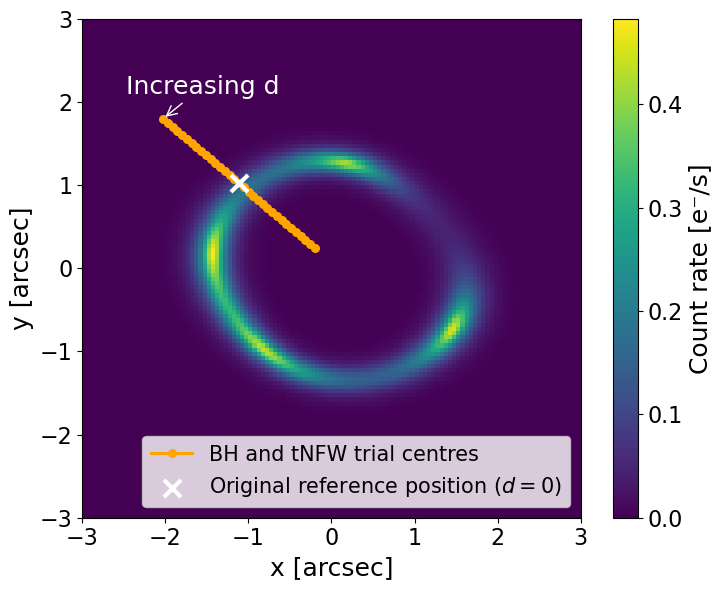

In [31]:
field_width = numpix * pixel_scale
extent = [-field_width / 2, field_width / 2, -field_width / 2, field_width / 2]

fig, ax = plt.subplots(figsize=(7.5, 6))

im = ax.imshow(baseline_bh, origin="lower", extent=extent, cmap="viridis")

ax.plot(
    positions_x, positions_y, "o-",
    color="orange",
    markersize=5.5,
    linewidth=2.2,
    label="BH and tNFW trial centres")



ax.annotate(
    "Increasing d",
    xy=(positions_x[-1], positions_y[-1]),
    xytext=(positions_x[-1] - 0.45, positions_y[-1] + 0.3),
    arrowprops={"arrowstyle": "->", "color": "white"},
    color="white",
    fontsize=18)

ax.scatter(
    [perturber_x], [perturber_y],
    marker="x",
    s=150,
    color="white",
    linewidths=3,
    zorder=10,
    label="Original reference position ($d=0$)")


ax.set_xlabel("x [arcsec]", fontsize=18)
ax.set_ylabel("y [arcsec]", fontsize=18)

ax.tick_params(axis="both", labelsize=16)

ax.legend(loc="lower right", fontsize=15)

# Increase colorbar text
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Count rate [e⁻/s]", fontsize=18)
cbar.ax.tick_params(labelsize=16)

plt.tight_layout()
plt.savefig("arc_distance_path.png", dpi=300, bbox_inches="tight")
plt.show()



In [7]:
rms_bh_distance = []
rms_nfw_distance = []
rms_bh_nfw_distance = []  
saved_distance_cases = []

for d, x, y in zip(distances, positions_x, positions_y):

    kwargs_bh = {
        "theta_E": theta_E_bh_fixed,
        "center_x": float(x),
        "center_y": float(y)}

    kwargs_nfw = {
        "Rs": rs_fixed,
        "alpha_Rs": alpha_Rs_fixed,
        "r_trunc": r_trunc,
        "center_x": float(x),
        "center_y": float(y)}

    image_bh = model_bh.image(
        kwargs_lens=kwargs_main_lens + [kwargs_bh],
        kwargs_source=kwargs_source)
    image_nfw = model_nfw.image(
        kwargs_lens=kwargs_main_lens + [kwargs_nfw],
        kwargs_source=kwargs_source)

    residual_bh = image_bh - baseline_bh
    residual_nfw = image_nfw - baseline_nfw
    difference_bh_nfw = image_bh - image_nfw

    bh_strength = np.sqrt(np.mean(residual_bh**2))
    nfw_strength = np.sqrt(np.mean(residual_nfw**2))
    direct_difference = np.sqrt(np.mean(difference_bh_nfw**2))

    rms_bh_distance.append(bh_strength)
    rms_nfw_distance.append(nfw_strength)
    rms_bh_nfw_distance.append(direct_difference)

    saved_distance_cases.append({
        "distance": float(d), "x": float(x), "y": float(y),
        "mass": M_sub_fixed,
        "image_bh": image_bh.copy(), "image_nfw": image_nfw.copy(),
        "residual_bh": residual_bh.copy(),
        "residual_nfw": residual_nfw.copy(),
        "difference_bh_nfw": difference_bh_nfw.copy()})

    print(f"d={d:.2f} arcsec | x={x:.3f}, y={y:.3f} | "
          f"BH RMS={bh_strength:.5g} | tNFW RMS={nfw_strength:.5g}")


d=-1.20 arcsec | x=-0.198, y=0.243 | BH RMS=0.012848 | tNFW RMS=0.01224
d=-1.12 arcsec | x=-0.255, y=0.292 | BH RMS=0.013085 | tNFW RMS=0.012432
d=-1.05 arcsec | x=-0.312, y=0.340 | BH RMS=0.013335 | tNFW RMS=0.01263
d=-0.97 arcsec | x=-0.369, y=0.389 | BH RMS=0.0136 | tNFW RMS=0.012832
d=-0.90 arcsec | x=-0.427, y=0.438 | BH RMS=0.013881 | tNFW RMS=0.013037
d=-0.82 arcsec | x=-0.484, y=0.486 | BH RMS=0.014184 | tNFW RMS=0.013248
d=-0.75 arcsec | x=-0.541, y=0.535 | BH RMS=0.014518 | tNFW RMS=0.013465
d=-0.67 arcsec | x=-0.598, y=0.584 | BH RMS=0.014899 | tNFW RMS=0.013695
d=-0.60 arcsec | x=-0.655, y=0.632 | BH RMS=0.015352 | tNFW RMS=0.013944
d=-0.53 arcsec | x=-0.712, y=0.681 | BH RMS=0.015914 | tNFW RMS=0.014226
d=-0.45 arcsec | x=-0.769, y=0.730 | BH RMS=0.016636 | tNFW RMS=0.014561
d=-0.38 arcsec | x=-0.826, y=0.779 | BH RMS=0.017566 | tNFW RMS=0.014972
d=-0.30 arcsec | x=-0.883, y=0.827 | BH RMS=0.018762 | tNFW RMS=0.015521
d=-0.22 arcsec | x=-0.940, y=0.876 | BH RMS=0.020295 | 

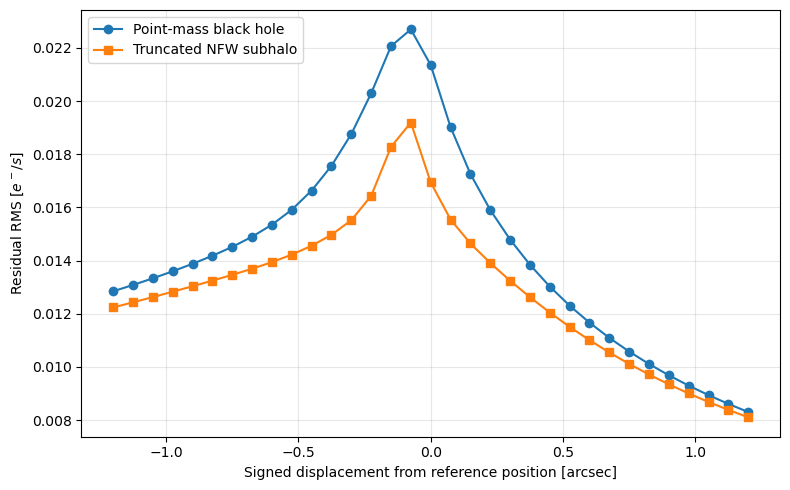

In [8]:
M_target = M_sub_fixed

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(distances, rms_bh_distance, "o-", label="Point-mass black hole")
ax.plot(distances, rms_nfw_distance, "s-", label="Truncated NFW subhalo")

ax.set_xlabel("Signed displacement from reference position [arcsec]")
ax.set_ylabel("Residual RMS [$e^-/s$]")
# ax.set_title("Lensing perturbation strength vs. distance from arc")
ax.grid(alpha=0.3)
ax.legend(loc="upper left")

plt.tight_layout()
plt.savefig("rms_vs_distance_from_arc.png", dpi=300, bbox_inches="tight")
plt.show()


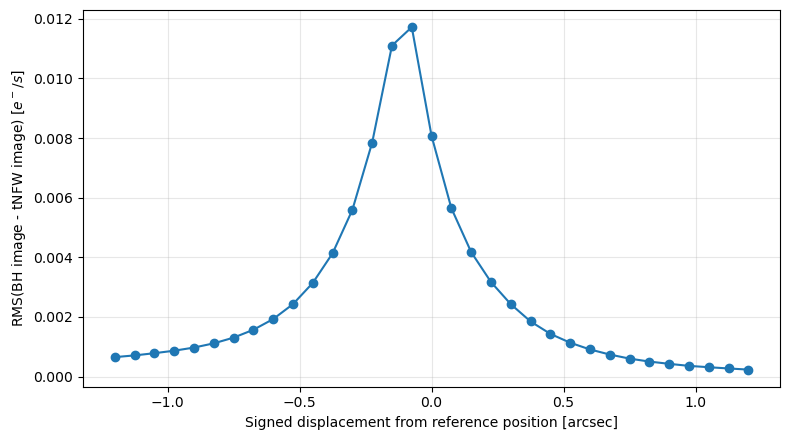

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(distances, rms_bh_nfw_distance, "o-")
ax.set_xlabel("Signed displacement from reference position [arcsec]")
ax.set_ylabel("RMS(BH image - tNFW image) [$e^-/s$]")
# ax.set_title("BH–tNFW image difference vs. distance")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("bh_tnfw_difference_vs_arc_distance.png", dpi=300, bbox_inches="tight")
plt.show()


In [10]:
import numpy as np

d = np.array(distances)

bh_idx = np.argmin(np.abs(d - 0.4))
nfw_idx = np.argmin(np.abs(d - 0.2))

bh_rms = rms_bh_distance[bh_idx]
nfw_rms = rms_nfw_distance[nfw_idx]

print(f"BH at d = {d[bh_idx]:.3f}: RMS = {bh_rms:.6f}")
print(f"tNFW at d = {d[nfw_idx]:.3f}: RMS = {nfw_rms:.6f}")

difference = abs(bh_rms - nfw_rms)
relative_difference = difference / nfw_rms * 100

print(f"Absolute RMS difference: {difference:.6f}")
print(f"Relative difference: {relative_difference:.2f}%")


BH at d = 0.375: RMS = 0.013845
tNFW at d = 0.225: RMS = 0.013912
Absolute RMS difference: 0.000067
Relative difference: 0.48%
